In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("heart.csv")

In [3]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


# EDA

In [4]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

In [5]:
df.shape

(918, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [7]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [8]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='HeartDisease'>

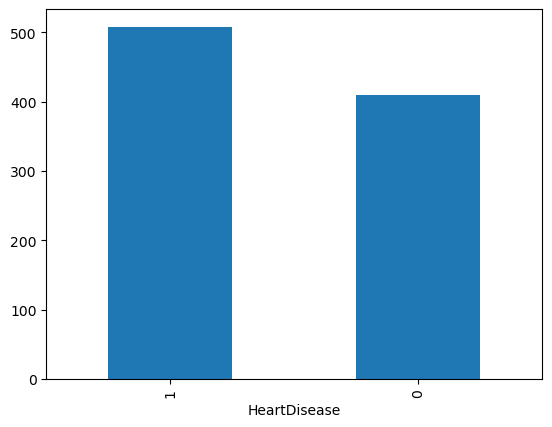

In [9]:
df['HeartDisease'].value_counts().plot(kind = "bar")

In [10]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

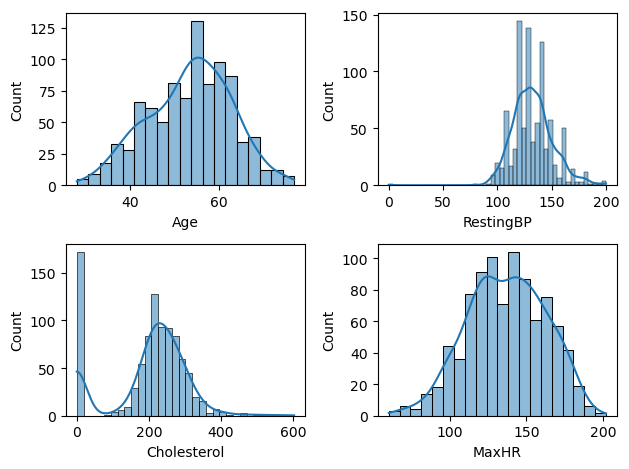

In [11]:
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde = True)

plotting('Age',1)
plotting('RestingBP',2)
plotting('Cholesterol',3)
plotting('MaxHR',4)


plt.tight_layout()

In [12]:
df['Cholesterol'].value_counts()

Cholesterol
0      172
254     11
223     10
220     10
230      9
      ... 
392      1
316      1
153      1
466      1
131      1
Name: count, Length: 222, dtype: int64

In [13]:
ch_mean = df.loc[df['Cholesterol'] != 0,'Cholesterol'].mean()

In [14]:
df['Cholesterol'] = df['Cholesterol'].replace(0,ch_mean)
df['Cholesterol'] = df['Cholesterol'].round(2)

In [15]:
resting_bp_mean = df.loc[df['RestingBP'] != 0, 'RestingBP'].mean()

df['RestingBP'] = df['RestingBP'].replace(0, resting_bp_mean)

df['RestingBP'] = df['RestingBP'].round(2)

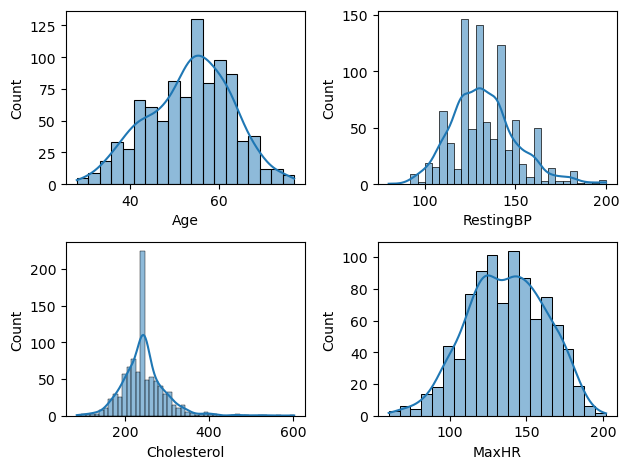

In [16]:
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde = True)

plotting('Age',1)
plotting('RestingBP',2)
plotting('Cholesterol',3)
plotting('MaxHR',4)


plt.tight_layout()

In [17]:
pip install sheryanalysis==0.1.0


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [18]:
import sheryanalysis as sh  
sh.analyze(df)



🔍 Basic Analysis Report


------------------------------------------------------------


📏 Shape: (918, 12)


🧱 Columns: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']



✅ No null values found



🔠 Categorical Columns: ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope', 'HeartDisease']



🔢 Numerical Columns: ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']


{'shape': (918, 12),
 'columns': ['Age',
  'Sex',
  'ChestPainType',
  'RestingBP',
  'Cholesterol',
  'FastingBS',
  'RestingECG',
  'MaxHR',
  'ExerciseAngina',
  'Oldpeak',
  'ST_Slope',
  'HeartDisease'],
 'dtypes': {'Age': dtype('int64'),
  'Sex': dtype('O'),
  'ChestPainType': dtype('O'),
  'RestingBP': dtype('float64'),
  'Cholesterol': dtype('float64'),
  'FastingBS': dtype('int64'),
  'RestingECG': dtype('O'),
  'MaxHR': dtype('int64'),
  'ExerciseAngina': dtype('O'),
  'Oldpeak': dtype('float64'),
  'ST_Slope': dtype('O'),
  'HeartDisease': dtype('int64')},
 'null_counts': {'Age': 0,
  'Sex': 0,
  'ChestPainType': 0,
  'RestingBP': 0,
  'Cholesterol': 0,
  'FastingBS': 0,
  'RestingECG': 0,
  'MaxHR': 0,
  'ExerciseAngina': 0,
  'Oldpeak': 0,
  'ST_Slope': 0,
  'HeartDisease': 0},
 'total_rows': 918,
 'column_types': {'categorical': ['Sex',
   'ChestPainType',
   'FastingBS',
   'RestingECG',
   'ExerciseAngina',
   'ST_Slope',
   'HeartDisease'],
  'numerical': ['Age', 'Rest

<Axes: xlabel='Sex', ylabel='count'>

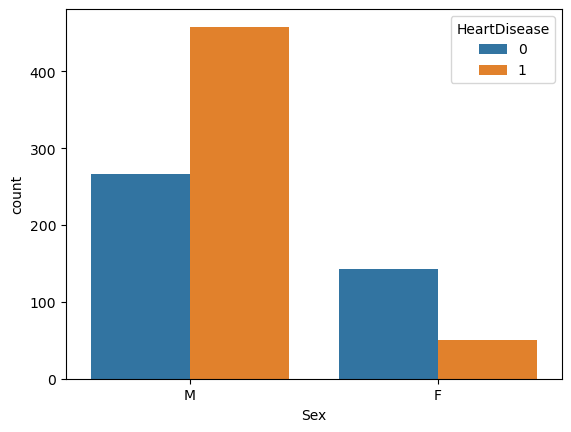

In [19]:
sns.countplot(x = df['Sex'],hue = df['HeartDisease'])

<Axes: xlabel='ChestPainType', ylabel='count'>

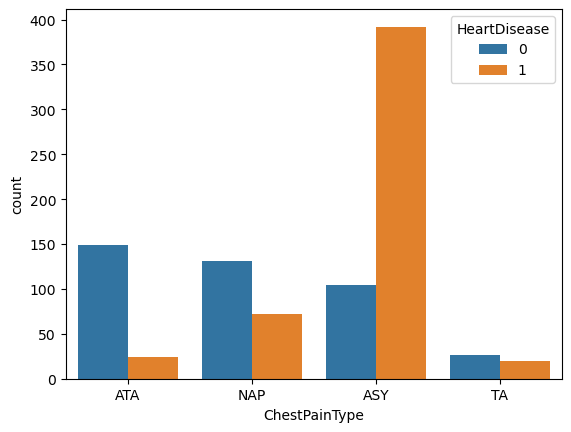

In [20]:
sns.countplot(x = df['ChestPainType'],hue = df['HeartDisease'])

<Axes: xlabel='FastingBS', ylabel='count'>

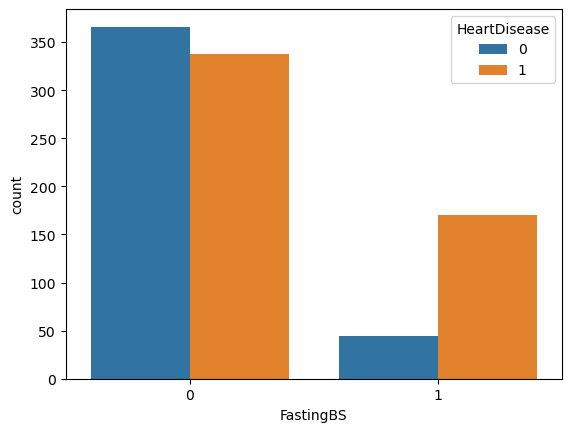

In [21]:
sns.countplot(x = df['FastingBS'],hue = df['HeartDisease'])

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

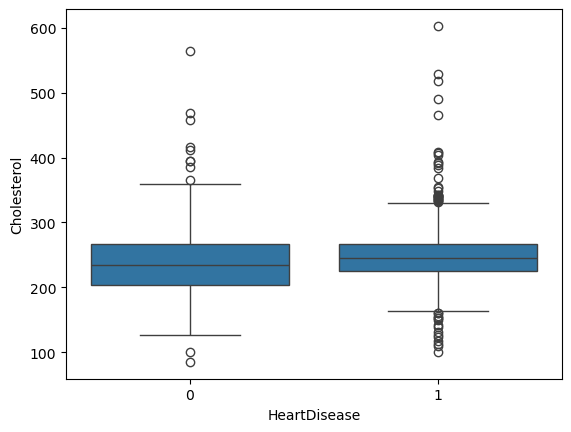

In [22]:
sns.boxplot(x = 'HeartDisease', y = 'Cholesterol',data = df)

<Axes: xlabel='HeartDisease', ylabel='Age'>

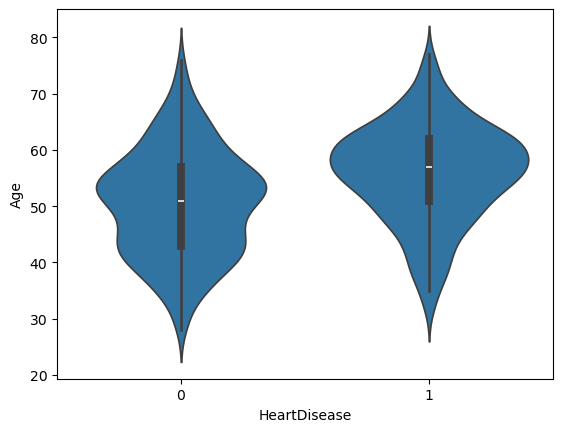

In [23]:
sns.violinplot(x='HeartDisease', y='Age', data=df)

<Axes: >

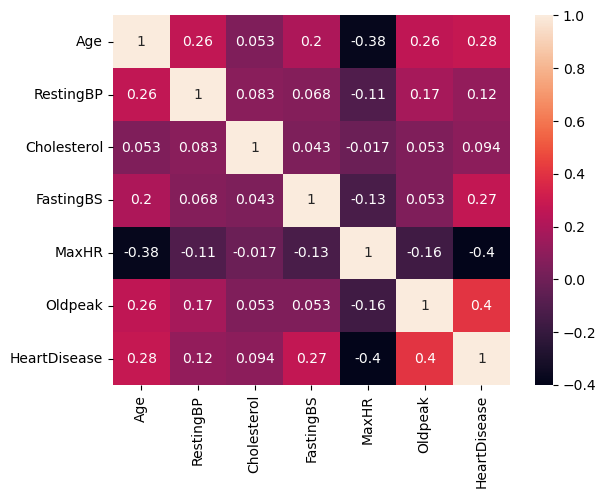

In [24]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

# Data perprocessing and cleaning 

In [25]:
df_encode = pd.get_dummies(df,drop_first=True)

In [26]:
df_encode

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140.0,289.0,0,172,0.0,0,True,True,False,False,True,False,False,False,True
1,49,160.0,180.0,0,156,1.0,1,False,False,True,False,True,False,False,True,False
2,37,130.0,283.0,0,98,0.0,0,True,True,False,False,False,True,False,False,True
3,48,138.0,214.0,0,108,1.5,1,False,False,False,False,True,False,True,True,False
4,54,150.0,195.0,0,122,0.0,0,True,False,True,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110.0,264.0,0,132,1.2,1,True,False,False,True,True,False,False,True,False
914,68,144.0,193.0,1,141,3.4,1,True,False,False,False,True,False,False,True,False
915,57,130.0,131.0,0,115,1.2,1,True,False,False,False,True,False,True,True,False
916,57,130.0,236.0,0,174,0.0,1,False,True,False,False,False,False,False,True,False


In [27]:
df_encode = df_encode.astype(int)

In [28]:
df_encode

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0,0,1,1,0,0,1,0,0,0,1
1,49,160,180,0,156,1,1,0,0,1,0,1,0,0,1,0
2,37,130,283,0,98,0,0,1,1,0,0,0,1,0,0,1
3,48,138,214,0,108,1,1,0,0,0,0,1,0,1,1,0
4,54,150,195,0,122,0,0,1,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264,0,132,1,1,1,0,0,1,1,0,0,1,0
914,68,144,193,1,141,3,1,1,0,0,0,1,0,0,1,0
915,57,130,131,0,115,1,1,1,0,0,0,1,0,1,1,0
916,57,130,236,0,174,0,1,0,1,0,0,0,0,0,1,0


In [29]:
from sklearn.preprocessing import StandardScaler
numerical_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
scaler = StandardScaler()
df_encode[numerical_cols] = scaler.fit_transform(df_encode[numerical_cols])
df_encode.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0.414885,0.834754,0,1.382928,-0.727592,0,1,1,0,0,1,0,0,0,1
1,-0.478484,1.527224,-1.210675,0,0.754157,0.282891,1,0,0,1,0,1,0,0,1,0
2,-1.751359,-0.141284,0.722161,0,-1.525138,-0.727592,0,1,1,0,0,0,1,0,0,1
3,-0.584556,0.303651,-0.572651,0,-1.132156,0.282891,1,0,0,0,0,1,0,1,1,0
4,0.051881,0.971054,-0.929194,0,-0.581981,-0.727592,0,1,0,1,0,1,0,0,0,1


# ------------------------------------------------------------------------------------
## 🚀 ADVANCED EDA & INTERVIEW MASTERY SECTION
### Topics Covered:
1. **Outlier Detection & Treatment**: IQR vs Z-Score, Capping (Winsorization) vs Trimming
2. **Distribution Analysis & Power Transformations**: Skewness, Kurtosis, Box-Cox & Yeo-Johnson
3. **Multicollinearity Diagnostics**: Variance Inflation Factor (VIF) & Correlation Matrix
4. **Statistical Hypothesis Testing**: Two-Sample T-test, Mann-Whitney U, Chi-Square Test of Independence
5. **Feature Scaling Comparison**: StandardScaler vs MinMaxScaler vs RobustScaler (Outlier Sensitivity)
6. **Feature Selection**: Mutual Information (`mutual_info_classif`) & ANOVA F-value (`f_classif`)
7. **Data Leakage Prevention**: Production-grade Pipeline formulation
8. **Interview Questions & Answers (Top 15 Tricky EDA & Preprocessing Questions)**
# ------------------------------------------------------------------------------------

### 1. Outlier Detection: IQR & Z-Score Analysis
- **IQR Rule**: Values $< Q_1 - 1.5 \times \text{IQR}$ or $> Q_3 + 1.5 \times \text{IQR}$ are potential outliers.
- **Z-Score Rule**: Values with $|Z| > 3$ ($>3$ standard deviations from the mean).
- **Treatment Options**: Capping (Winsorization) preserves sample size without skewing variance, whereas Trimming removes rows.

In [30]:
# Outlier summary using IQR method on numerical columns
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
outlier_stats = []

for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    n_outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[0]
    pct_outliers = (n_outliers / len(df)) * 100
    outlier_stats.append({
        'Feature': col,
        'Q1': q1, 'Q3': q3, 'IQR': iqr,
        'Lower Bound': lower_bound, 'Upper Bound': upper_bound,
        'Outlier Count': n_outliers, '% Outliers': f"{pct_outliers:.2f}%"
    })

outlier_df = pd.DataFrame(outlier_stats)
print("=== IQR OUTLIER AUDIT ===")
outlier_df

=== IQR OUTLIER AUDIT ===


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,% Outliers
0,Age,47.0,60.0,13.0,27.50,79.50,0,0.00%
1,RestingBP,120.0,140.0,20.0,90.00,170.00,27,2.94%
2,Cholesterol,214.0,267.0,53.0,134.50,346.50,41,4.47%
3,MaxHR,120.0,156.0,36.0,66.00,210.00,2,0.22%
4,Oldpeak,0.0,1.5,1.5,-2.25,3.75,16,1.74%


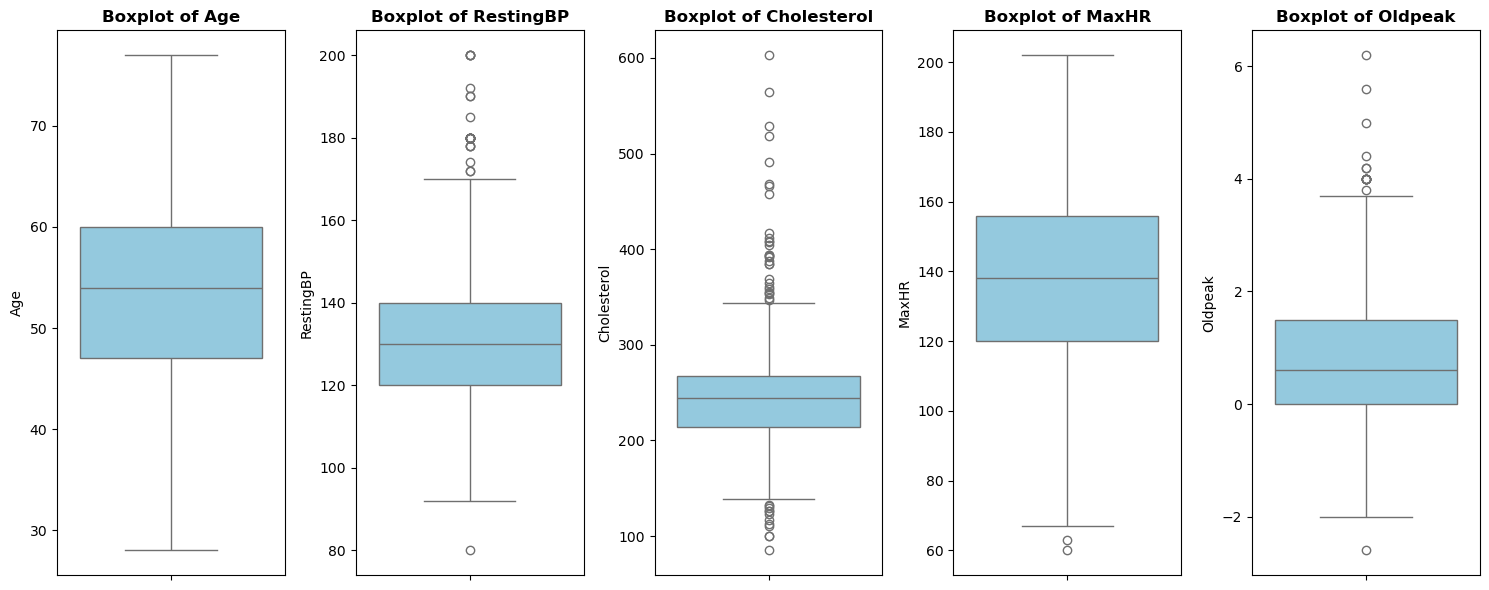

In [31]:
# Visualizing Outliers across Numerical Features
plt.figure(figsize=(15, 6))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 5, i)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontweight='bold')
plt.tight_layout()
plt.show()

### 2. Outlier Treatment: Winsorization (Percentile Capping)
Instead of dropping patient records, we cap extreme tails at the 1st and 99th percentiles.

In [32]:
df_capped = df.copy()
for col in ['RestingBP', 'Cholesterol', 'Oldpeak']:
    lower_limit = df_capped[col].quantile(0.01)
    upper_limit = df_capped[col].quantile(0.99)
    df_capped[col] = np.clip(df_capped[col], lower_limit, upper_limit)

print("Original max Cholesterol:", df['Cholesterol'].max(), "--> Capped max:", df_capped['Cholesterol'].max())
print("Original max RestingBP:", df['RestingBP'].max(), "--> Capped max:", df_capped['RestingBP'].max())

Original max Cholesterol: 603.0 --> Capped max: 411.4900000000001
Original max RestingBP: 200.0 --> Capped max: 180.0


### 3. Skewness & Kurtosis Analysis + Power Transformations
- **Rule of Thumb**:
  - $|	ext{Skewness}| < 0.5$: Approximately symmetric
  - $0.5 < |\text{Skewness}| < 1.0$: Moderately skewed
  - $|\text{Skewness}| > 1.0$: Highly skewed (violates normality assumptions of linear models and distance metrics)
- **Transformation**:
  - `Log1p`: $y = \log(1 + x)$ for non-negative data
  - `Yeo-Johnson`: Power transformation that handles positive and negative values (unlike Box-Cox which requires strictly $>0$)

In [33]:
skew_kurt_df = pd.DataFrame({
    'Skewness': df[num_cols].skew(),
    'Kurtosis': df[num_cols].kurtosis()
})
print("=== SKEWNESS & KURTOSIS BEFORE TRANSFORMATION ===")
display(skew_kurt_df)

# Apply Yeo-Johnson Power Transformation
from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method='yeo-johnson')
df_transformed = df.copy()
df_transformed[num_cols] = pt.fit_transform(df[num_cols])

print("=== SKEWNESS AFTER YEO-JOHNSON TRANSFORMATION ===")
print(df_transformed[num_cols].skew())

=== SKEWNESS & KURTOSIS BEFORE TRANSFORMATION ===


,Skewness,Kurtosis
Age,-0.195933,-0.386140
RestingBP,0.607525,0.795985
Cholesterol,1.373348,6.257714
MaxHR,-0.144359,-0.448248
Oldpeak,1.022872,1.203064


=== SKEWNESS AFTER YEO-JOHNSON TRANSFORMATION ===
Age           -0.040825
RestingBP     -0.004138
Cholesterol    0.024681
MaxHR         -0.041028
Oldpeak       -0.301161
dtype: float64


### 4. Multicollinearity Diagnostics: Variance Inflation Factor (VIF)
- $\text{VIF}_j = \frac{1}{1 - R_j^2}$ where $R_j^2$ is the coefficient of determination from regressing feature $j$ on all other features.
- $\text{VIF} = 1$: No correlation
- $1 < \text{VIF} < 5$: Moderate correlation (safe)
- $\text{VIF} > 5$ or $10$: Severe multicollinearity (inflates standard errors of coefficients in linear models)!

In [34]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Note: Standardizing features before VIF prevents artificial inflation due to scale/mean offsets
X_num = StandardScaler().fit_transform(df[num_cols])
vif_results = pd.DataFrame({
    'Feature': num_cols,
    'VIF': [variance_inflation_factor(X_num, i) for i in range(len(num_cols))]
})
print("=== VARIANCE INFLATION FACTOR (VIF) ===")
display(vif_results.sort_values(by='VIF', ascending=False))

=== VARIANCE INFLATION FACTOR (VIF) ===


,Feature,VIF
0,Age,1.288118
3,MaxHR,1.176613
1,RestingBP,1.093482
4,Oldpeak,1.092105
2,Cholesterol,1.009160


### 5. Statistical Hypothesis Testing for Feature Significance
1. **Continuous Features vs Binary Target (`HeartDisease`)**:
   - **Two-Sample Independent T-Test**: Parametric test comparing means.
   - **Mann-Whitney U Test**: Non-parametric test (robust against outliers/skewness).
2. **Categorical Features vs Binary Target**:
   - **Chi-Square ($\chi^2$) Test of Independence**: Tests if category distributions differ significantly between diseased vs healthy patients.

In [35]:
from scipy import stats

stat_results = []
# 1. Numerical features hypothesis testing
for col in num_cols:
    group0 = df[df['HeartDisease'] == 0][col]
    group1 = df[df['HeartDisease'] == 1][col]
    t_stat, t_pval = stats.ttest_ind(group0, group1)
    u_stat, u_pval = stats.mannwhitneyu(group0, group1)
    stat_results.append({
        'Feature': col,
        'Type': 'Numerical',
        'Test': 'Two-sample T-test',
        'p-value': f"{t_pval:.4e}",
        'Significant (p < 0.05)': 'YES' if t_pval < 0.05 else 'NO'
    })

# 2. Categorical features hypothesis testing
cat_cols = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
for col in cat_cols:
    contingency_table = pd.crosstab(df[col], df['HeartDisease'])
    chi2_stat, chi2_pval, dof, _ = stats.chi2_contingency(contingency_table)
    stat_results.append({
        'Feature': col,
        'Type': 'Categorical',
        'Test': 'Chi-Square Test',
        'p-value': f"{chi2_pval:.4e}",
        'Significant (p < 0.05)': 'YES' if chi2_pval < 0.05 else 'NO'
    })

hypo_df = pd.DataFrame(stat_results)
print("=== STATISTICAL SIGNIFICANCE SUMMARY ===")
display(hypo_df)

=== STATISTICAL SIGNIFICANCE SUMMARY ===


,Feature,Type,Test,p-value,Significant (p < 0.05)
0,Age,Numerical,Two-sample T-test,3.0080e-18,YES
1,RestingBP,Numerical,Two-sample T-test,3.4230e-04,YES
2,Cholesterol,Numerical,Two-sample T-test,4.3310e-03,YES
3,MaxHR,Numerical,Two-sample T-test,1.1378e-36,YES
4,Oldpeak,Numerical,Two-sample T-test,2.3908e-37,YES
5,Sex,Categorical,Chi-Square Test,4.5976e-20,YES
6,ChestPainType,Categorical,Chi-Square Test,8.0837e-58,YES
7,FastingBS,Categorical,Chi-Square Test,1.0573e-15,YES
8,RestingECG,Categorical,Chi-Square Test,4.2292e-03,YES
9,ExerciseAngina,Categorical,Chi-Square Test,2.9078e-50,YES


### 6. Feature Scaling In-Depth: StandardScaler vs MinMaxScaler vs RobustScaler
- **StandardScaler**: $z = \frac{x - \mu}{\sigma}$ (Zero mean, unit variance. Sensitive to outliers!)
- **MinMaxScaler**: $x_{\text{norm}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$ (Compresses into $[0, 1]$. Outliers crush normal values into tiny range!)
- **RobustScaler**: $x_{\text{robust}} = \frac{x - Q_2}{Q_3 - Q_1} = \frac{x - \text{median}}{\text{IQR}}$ (Outlier-resistant because median & IQR are not influenced by extreme tails).

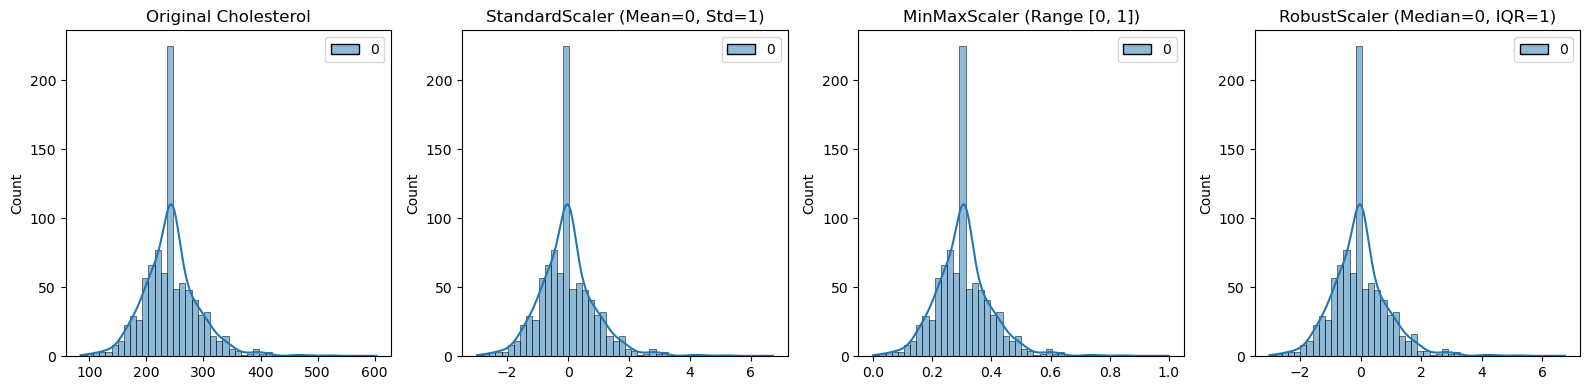

In [36]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

sample_col = df['Cholesterol'].values.reshape(-1, 1)

ss_vals = StandardScaler().fit_transform(sample_col)
mms_vals = MinMaxScaler().fit_transform(sample_col)
rs_vals = RobustScaler().fit_transform(sample_col)

plt.figure(figsize=(16, 4))
plt.subplot(1, 4, 1)
sns.histplot(sample_col, kde=True, color='gray')
plt.title('Original Cholesterol')

plt.subplot(1, 4, 2)
sns.histplot(ss_vals, kde=True, color='blue')
plt.title('StandardScaler (Mean=0, Std=1)')

plt.subplot(1, 4, 3)
sns.histplot(mms_vals, kde=True, color='green')
plt.title('MinMaxScaler (Range [0, 1])')

plt.subplot(1, 4, 4)
sns.histplot(rs_vals, kde=True, color='purple')
plt.title('RobustScaler (Median=0, IQR=1)')
plt.tight_layout()
plt.show()

### 7. Feature Selection: Mutual Information & ANOVA F-Score
- **Mutual Information (MI)**: Measures both **linear AND non-linear** dependencies between features and the target. $\text{MI} \ge 0$, where 0 means complete independence.
- **ANOVA F-value**: Measures ratio of between-group variance to within-group variance (assumes linear relationship).

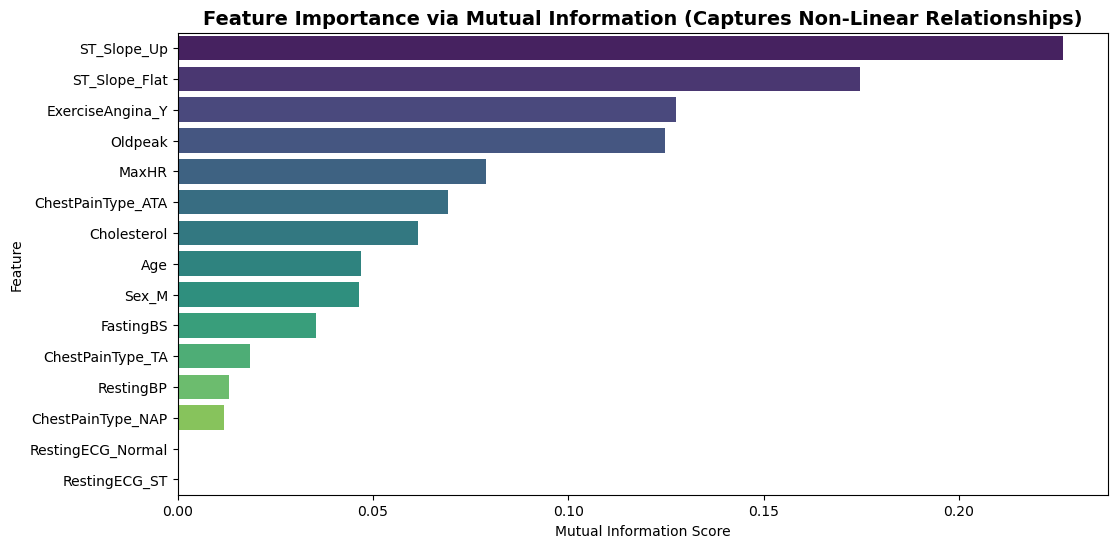

In [37]:
from sklearn.feature_selection import mutual_info_classif, f_classif

df_onehot = pd.get_dummies(df, drop_first=True)
X_all = df_onehot.drop('HeartDisease', axis=1)
y_all = df_onehot['HeartDisease']

mi_scores = mutual_info_classif(X_all, y_all, random_state=42)
f_scores, f_pvals = f_classif(X_all, y_all)

feat_rank_df = pd.DataFrame({
    'Feature': X_all.columns,
    'Mutual_Information': mi_scores,
    'ANOVA_F_Score': f_scores
}).sort_values(by='Mutual_Information', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x='Mutual_Information', y='Feature', data=feat_rank_df, palette='viridis')
plt.title('Feature Importance via Mutual Information (Captures Non-Linear Relationships)', fontsize=14, fontweight='bold')
plt.xlabel('Mutual Information Score')
plt.show()

### 8. Production-Grade Pipeline (Preventing Data Leakage)
#### ⚠️ Critical Interview Rule: Data Leakage Prevention
- **Never** fit scalers, imputers, or encoders on the complete dataset before train/test splitting.
- Preprocessing statistics (means, standard deviations, min, max, median) must be computed **ONLY on `X_train`** and applied downstream to `X_test` via `transform()`.

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

X_raw = df.drop('HeartDisease', axis=1)
y_raw = df['HeartDisease']

X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42, stratify=y_raw)

numeric_features = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
categorical_features = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

pipeline.fit(X_tr, y_tr)
y_preds = pipeline.predict(X_te)

print("=== LEAK-FREE PIPELINE CLASSIFICATION REPORT ===")
print(classification_report(y_te, y_preds))

=== LEAK-FREE PIPELINE CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.88      0.84      0.86        82
           1       0.88      0.91      0.89       102

    accuracy                           0.88       184
   macro avg       0.88      0.88      0.88       184
weighted avg       0.88      0.88      0.88       184



### 9. Top 15 Machine Learning Interview Questions: EDA & Preprocessing

| # | Question | Concise Expert Answer |
|---|---|---|
| **1** | **What is Data Leakage and how do you prevent it?** | Data leakage occurs when test set information leaks into the training phase (e.g., standardizing using full dataset mean/variance, or doing target encoding on all rows). Prevention: Always split data first, fit transformers only on `X_train`, and use `sklearn.pipeline.Pipeline`. |
| **2** | **When should you choose RobustScaler over StandardScaler?** | When the dataset contains significant outliers. StandardScaler uses sample mean and variance which are heavily distorted by extreme values. RobustScaler subtracts the median and divides by IQR, resisting outlier corruption. |
| **3** | **What is the difference between Trimming and Winsorization?** | Trimming drops rows with outlier values, which reduces dataset size and can bias distributions. Winsorization (capping) clamps extreme values at percentiles (e.g. 1st and 99th), keeping sample size intact. |
| **4** | **What is the Variance Inflation Factor (VIF)?** | $\text{VIF} = \frac{1}{1 - R_j^2}$. It quantifies how much multicollinearity inflates the variance of an estimated regression coefficient. VIF > 5-10 indicates problematic collinearity. |
| **5** | **Why does multicollinearity hurt Linear models but not Tree-based models?** | Linear regression relies on matrix inversion $(X^T X)^{-1}$. Collinearity makes $X^T X$ near-singular, causing unstable coefficient estimates and high variance. Decision trees evaluate one split at a time on single features, so collinear features do not destabilize the tree structure. |
| **6** | **When to use Pearson vs Spearman vs Kendall correlation?** | Pearson measures **linear** relationships in continuous, normally distributed data. Spearman rank correlation measures **monotonic** relationships (handles non-linear curves and outliers). Kendall's Tau is best for small sample sizes and ordinal rankings. |
| **7** | **What is the difference between One-Hot Encoding and Target Encoding?** | One-Hot creates $K$ (or $K-1$) binary dummy columns; causes dimensionality explosion for high-cardinality features. Target Encoding replaces categories with the mean target value; compact ($1$ column) but prone to target leakage/overfitting without K-fold regularization/smoothing. |
| **8** | **What is the Dummy Variable Trap?** | When $K$ categorical states are converted to $K$ one-hot columns with an intercept present, the columns sum to 1, causing perfect multicollinearity. Fix: Drop one column using `drop='first'`. |
| **9** | **When is Box-Cox used vs Yeo-Johnson?** | Both are power transformations to make data normally distributed. Box-Cox strictly requires all values $> 0$. Yeo-Johnson can handle zero and negative values. |
| **10** | **Why is Mutual Information better than Pearson correlation for feature selection?** | Pearson only captures linear relationships ($y = mx + c$). Mutual Information captures arbitrary non-linear relationships (e.g. $y = x^2$ where Pearson correlation is 0). |
| **11** | **How do you handle missing values in time-series vs cross-sectional data?** | For cross-sectional data: Mean/median/mode imputation, KNNImputer, or IterativeImputer (MICE). For time-series: Forward-fill (`ffill`), backward-fill, linear/spline interpolation; never use future values (prevents lookahead bias). |
| **12** | **Do tree models require feature scaling?** | No. Trees are invariant to monotonic transformations because split decisions only depend on rank/ordering of values along each feature axis, not absolute magnitudes. |
| **13** | **Why does KNN require feature scaling?** | KNN uses distance metrics (Euclidean/Manhattan). If feature $A$ has range $[0, 100000]$ and feature $B$ has range $[0, 1]$, distance is completely dominated by feature $A$. |
| **14** | **What is Simpson's Paradox?** | A statistical phenomenon where a trend appears across several groups of data but disappears or reverses when the groups are combined. Identified via stratified bivariate EDA. |
| **15** | **How does SMOTE work for class imbalance?** | Synthetic Minority Over-sampling Technique picks minority class samples, finds their $k$-nearest neighbors, and generates synthetic points along the connecting line segments in feature space. Applied ONLY to training data. |